# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiones **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados** con gráficos que respalden las conclusiones.

Se aplican **pruebas estadísticas apropiadas** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import levene
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**:
- No se identifican valores nulos en el dataset.
- Los tipos de datos de las columnas son adecuados para la información que representan.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
df["user_id"].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df[df["converted"] == 1].describe()

,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nResumen estadístico de categorías:")
df[["landing", "region", "dispositivo", "traffic_source", "user_type"]].apply(lambda x: x.describe())


Resumen estadístico de categorías:


,landing,region,dispositivo,traffic_source,user_type
count,40000,40000,40000,40000,40000
unique,2,5,2,4,2
top,B,Norte,Mobile,Organic,Nuevo
freq,20018,11166,24829,17987,26033


In [11]:
print("\nDistribución de categorías:")
df[["landing", "region", "dispositivo", "traffic_source", "user_type"]].apply(lambda x: x.value_counts())


Distribución de categorías:


,landing,region,dispositivo,traffic_source,user_type
A,19982.0,NaN,NaN,NaN,NaN
Ads,NaN,NaN,NaN,11935.0,NaN
B,20018.0,NaN,NaN,NaN,NaN
Centro,NaN,9613.0,NaN,NaN,NaN
Desktop,NaN,NaN,15171.0,NaN,NaN
Email,NaN,NaN,NaN,6123.0,NaN
Mobile,NaN,NaN,24829.0,NaN,NaN
Norte,NaN,11166.0,NaN,NaN,NaN
Nuevo,NaN,NaN,NaN,NaN,26033.0
Occidente,NaN,6398.0,NaN,NaN,NaN


✍️ **Comentario**: 
- No se identificaron errores en las variables categóricas. Todas las categorías corresponden a valores esperados para las variables analizadas.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:
# Gasto por versión
gasto_A = df[(df["landing"] == "A") & (df["converted"]==1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"]==1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [13]:
l_stat, p_value_var = levene(gasto_A, gasto_B)
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p:{p_value_var}")

Estadístico de Levene: 29.17646453202917
Valor p:6.875301988016449e-08


### Prueba T de Welch

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los clientes que compran es igual en la página A y en la página B
- **Hipótesis alternativa (H₁):** El gasto promedio de los clientes que compran es distinto entre la página A y la página B

In [14]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor p: {p_value}")

Estadístico t: -9.48101092267275
Valor p: 3.627602231521493e-21


In [15]:
print("Promedio de gasto A:",gasto_A.mean())

Promedio de gasto A: 61.0865724522293


In [16]:
print("Promedio de gasto B:",gasto_B.mean())

Promedio de gasto B: 68.74536005009392


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (p ≈ 3.6e-21 < 0.05): existe evidencia estadísticamente significativa de que el gasto promedio es distinto entre la página A y la B. Se utilizó la prueba t de Welch porque la prueba de Levene indicó varianzas diferentes entre los grupos (p ≈ 6.9e-08).

**Interpretación de negocio:**  
El gasto promedio es mayor en el grupo B, con una diferencia de aproximadamente 7.66 respecto al grupo A. Además, la prueba estadística indica que esta diferencia es significativa, por lo que existe evidencia suficiente para considerar que la página B genera un mayor gasto promedio por usuario convertido que la página A.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z 

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe diferencia en la tasa de conversión entre A y B. Es decir, las tasas son iguales.
- **Hipótesis alternativa (H₁):** Sí existe una diferencia en la tasa de conversión entre A y B. Es decir, las tasas son diferentes.

In [17]:
# Número de usuarios convertidos por página
conversiones=df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales=df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [18]:
exitos=[conversiones["A"],conversiones["B"]]
observaciones = [totales["A"], totales ["B"]]

In [19]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitos,observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


In [20]:
print("Comparación de tasas de éxito:")
tasa_A = exitos[0]/observaciones[0]
tasa_B = exitos[1]/observaciones[1]
print(f"Tasa de conversión, página A: {tasa_A:.2%}")
print(f"Tasa de conversión, página B: {tasa_B:.2%}")

Comparación de tasas de éxito:
Tasa de conversión, página A: 12.57%
Tasa de conversión, página B: 15.96%


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (p ≈ 3.76e-22 < 0.05): existe evidencia estadísticamente significativa de que las tasas de conversión de las páginas A y B son diferentes. 

**Interpretación de negocio:**  
La página B presenta una tasa de conversión mayor (15.96%) que la página A (12.57%), una diferencia de aproximadamente 3.39 puntos porcentuales. Dado que esta diferencia es estadísticamente significativa, es muy poco probable que se deba al azar, por lo que la página B tiene un mejor desempeño en conversión.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba V de Cramér

**Hipótesis:**
- **Hipótesis nula (H₀):** La conversión es independiente de la fuente de tráfico. Es decir, la probabilidad de convertir es la misma sin importar por qué canal llegó el usuario (Ads, Email, Organic o Referral).
- **Hipótesis alternativa (H₁):** La conversión no es independiente de la fuente de tráfico. Es decir, al menos un canal tiene una tasa de conversión distinta a los demás.

In [21]:
tabla_normalizada = pd.crosstab(df["traffic_source"], df["converted"],normalize="index")*100
tabla = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla_normalizada)
chi2, p, dof, expected = chi2_contingency(tabla)
print()
print("Chi-cuadrada:", chi2)
print("Valor p:", p)
print("Grados de libertad:", dof)
print("Mínimo de frecuencias esperadas:", expected.min())

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163

Chi-cuadrada: 8.662108841397938
Valor p: 0.0341375947833914
Grados de libertad: 3
Mínimo de frecuencias esperadas: 564.18075


In [22]:
# Aplicar prueba
n=tabla.sum().sum()
cramers_v= np.sqrt(chi2/(n*(min(tabla.shape)-1)))
print("Coeficiente V de cramer:", cramers_v)

Coeficiente V de cramer: 0.014715730394205666


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (p = 0.034 < 0.05): hay evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**  
Email es el canal con mayor tasa de conversión (14.99%) y Organic el de menor (13.79%), una diferencia de apenas 1.2 puntos porcentuales. Aunque la asociación es estadísticamente significativa, su fuerza es prácticamente nula (V de Cramér = 0.015), por lo que la fuente de tráfico influye muy poco en la probabilidad de convertir. 

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión


Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.


### Prueba Chi-Cuadrada

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario es independiente de la conversión: la probabilidad de convertir es la misma para usuarios nuevos y recurrentes.
- **Hipótesis alternativa (H₁):** El tipo de usuario no es independiente de la conversión: la probabilidad de convertir es distinta entre usuarios nuevos y recurrentes.

In [23]:
tabla_normalizada = pd.crosstab(df["user_type"], df["converted"],normalize="index")*100
tabla = pd.crosstab(df["user_type"], df["converted"])
print(tabla_normalizada)

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


In [24]:
# Aplicar prueba
chi2_stat, p, dof, expected = chi2_contingency(tabla)
print("Resultado prueba Chi-Cuadrada:")
print()
print("Chi-cuadrada:", chi2_stat)
print("Valor p:", p)
print("Grados de libertad:", dof)
print("Mínimo de frecuencias esperadas:", expected.min())

Resultado prueba Chi-Cuadrada:

Chi-cuadrada: 0.5134849494478645
Valor p: 0.4736341272301974
Grados de libertad: 1
Mínimo de frecuencias esperadas: 1992.39255


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula (p = 0.4736 > 0.05). No hay evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión: los datos son compatibles con que la probabilidad de convertir sea la misma para usuarios nuevos y recurrentes.

**Interpretación de negocio:**  
Los usuarios nuevos presentan una tasa de conversión ligeramente mayor (14.36%) que los recurrentes (14.09%), una diferencia de apenas 0.27 puntos porcentuales. Sin embargo, esta diferencia no es estadísticamente significativa (p = 0.474) y es compatible con la variación del azar. Por lo tanto, no hay evidencia de que el tipo de usuario esté asociado a la conversión, y los resultados no justifican implementar estrategias distintas para usuarios nuevos y recurrentes.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

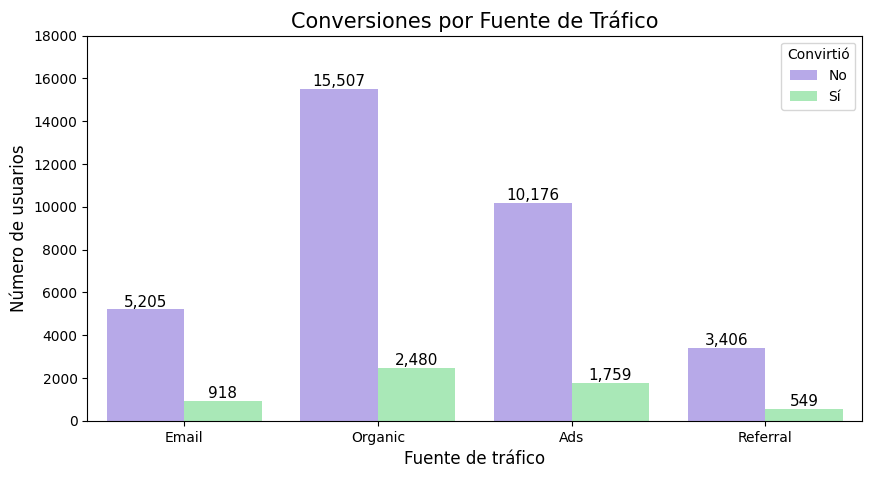

In [25]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data=df, x="traffic_source", hue="converted", palette=["#B19FF2","#9FF2B1"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x() + bar.get_width()/2,
            y=height,
            s=f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=11)

plt.title("Conversiones por Fuente de Tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.ylabel("Número de usuarios", fontsize=12)
plt.ylim(0, 18000)
plt.legend(title="Convirtió", labels=["No", "Sí"])
plt.show()

✍️ **Comentario**:
- Organic es el canal con mayor volumen de conversiones (2,480 usuarios), seguido de Ads (1,759), Email (918) y Referral (549). Esto se debe en gran parte a que Organic es también el canal que más usuarios aporta (17,987), por lo que su mayor volumen refleja el tamaño del canal y no necesariamente una mayor efectividad. En todos los canales, los usuarios que no convirtieron superan ampliamente a los que sí lo hicieron.

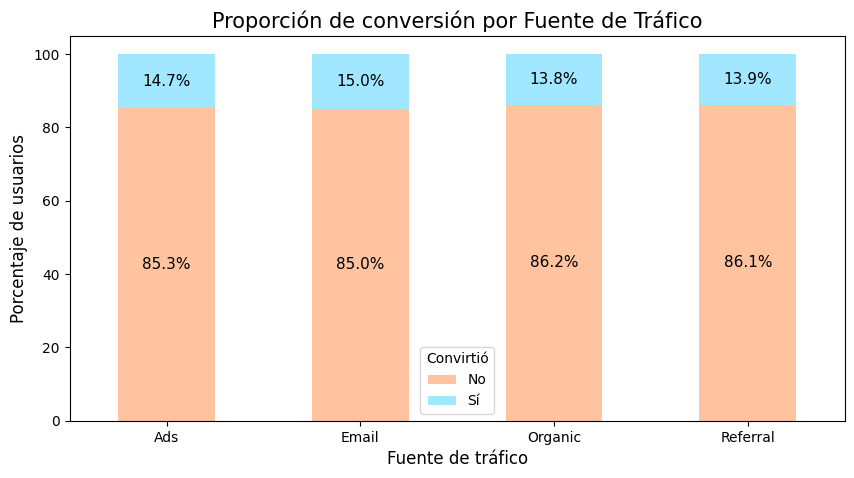

In [26]:
tabla_normalizada = pd.crosstab(df["traffic_source"], df["converted"],normalize="index")*100
ax = tabla_normalizada.plot(kind="bar",
                     stacked=True,
                     figsize=(10, 5),
                     color=["#FFC3A0", "#A0E7FF"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x() + bar.get_width()/2,
            y=bar.get_y() + height/2,
            s=f"{height:.1f}%",
            ha="center",
            va="center",
            fontsize=11)
    
plt.title("Proporción de conversión por Fuente de Tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico", fontsize=12)
plt.ylabel("Porcentaje de usuarios", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Convirtió", labels=["No", "Sí"])
plt.show()

✍️ **Comentario**: 
- Email es el canal más efectivo, con una tasa de conversión de 14.99%, mientras que Organic presenta la más baja, con 13.79%. Sin embargo, la diferencia entre ambos es de apenas 1.2 puntos porcentuales y las barras se ven casi idénticas entre canales. Esto contrasta con el gráfico de conteos, donde Organic lidera en volumen de conversiones: su mayor número se debe al tamaño del canal y no a una mayor efectividad. Esta similitud entre proporciones es coherente con la prueba chi-cuadrada y la V de Cramér, que indican una asociación estadísticamente significativa (p = 0.034) pero muy débil (V = 0.015).

### Relación entre el tipo de usuario y la conversión

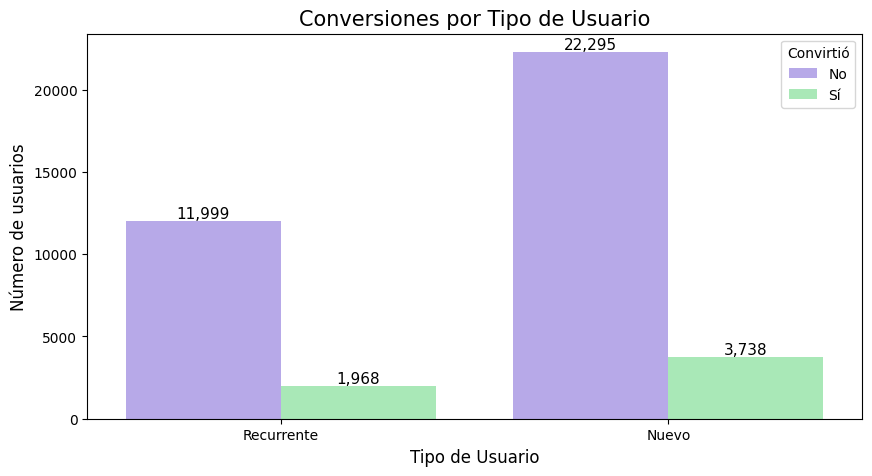

In [27]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data=df, x="user_type", hue="converted", palette=["#B19FF2","#9FF2B1"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x() + bar.get_width()/2,
            y=height,
            s=f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=11)

plt.title("Conversiones por Tipo de Usuario", fontsize=15)
plt.xlabel("Tipo de Usuario", fontsize=12)
plt.ylabel("Número de usuarios", fontsize=12)
plt.legend(title="Convirtió", labels=["No", "Sí"])
plt.show()

✍️ **Comentario**: 
- Los usuarios nuevos son el grupo más grande y también el que aporta el mayor número de conversiones (3,738). Esto se debe principalmente al tamaño del grupo y no a una mayor efectividad. En ambos tipos de usuario, quienes no convirtieron superan ampliamente a quienes sí lo hicieron.

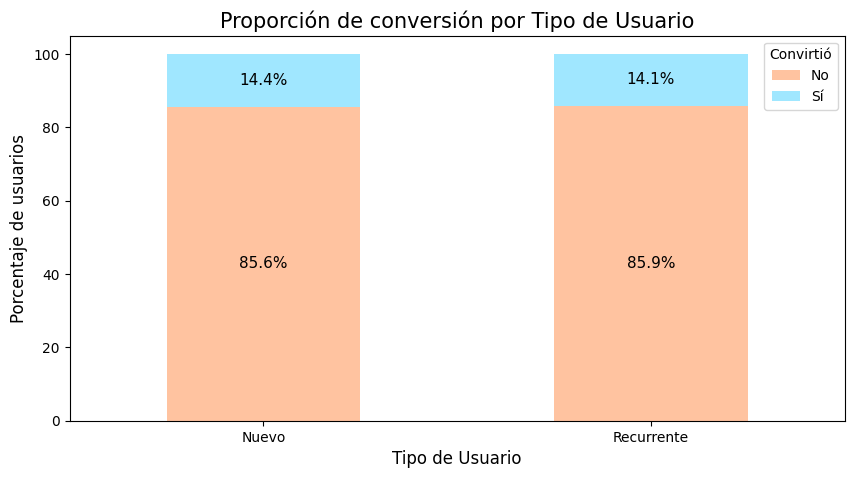

In [28]:
tabla_normalizada = pd.crosstab(df["user_type"], df["converted"],normalize="index")*100
ax = tabla_normalizada.plot(kind="bar",
                     stacked=True,
                     figsize=(10, 5),
                     color=["#FFC3A0", "#A0E7FF"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x() + bar.get_width()/2,
            y=bar.get_y() + height/2,
            s=f"{height:.1f}%",
            ha="center",
            va="center",
            fontsize=11)
    
plt.title("Proporción de conversión por Tipo de Usuario", fontsize=15)
plt.xlabel("Tipo de Usuario", fontsize=12)
plt.ylabel("Porcentaje de usuarios", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Convirtió", labels=["No", "Sí"])
plt.show()

✍️ **Comentario**:
- Los usuarios nuevos presentan una tasa de conversión ligeramente mayor (14.4%) que los recurrentes (14.1%), una diferencia de apenas 0.3 puntos porcentuales; en el gráfico, las barras se ven casi idénticas. Aunque los nuevos aportan más conversiones en volumen, esto se debe a que son el grupo más grande, no a que sean más efectivos. Esta similitud es coherente con la prueba chi-cuadrada (p = 0.474), que no encontró una asociación estadísticamente significativa entre el tipo de usuario y la conversión.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?

---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  


**Gasto promedio por usuario que convirtió:**
- Página A: $61.09 de gasto promedio
- Página B: $68.75 de gasto promedio
- **Interpretación:** Los clientes de la página B gastan en promedio $7.66 más (≈12.5%). La diferencia es estadísticamente significativa.

<br>

**Tasa de conversión:** 
- Página A: 12.57%
- Página B: 15.96%
- **Interpretación:** La página B convierte 3.39 puntos porcentuales más que la A. La diferencia también es estadísticamente significativa, es decir, no se explica por el azar.

**CONCLUSIÓN:**
- Conclusión: La página B supera a la A en las dos métricas: más usuarios compran y cada comprador gasta más. Se recomienda implementar la versión B.
  
---

#### 📊 **Segmentación por fuente de tráfico**
- Organic es el canal con mayor volumen de conversiones (2,480 usuarios), debido a que es también el que más usuarios aporta. En cuanto a efectividad, Email presenta la tasa de conversión más alta (15.0%), seguido de Ads (14.7%), mientras que Organic (13.8%) y Referral (13.9%) tienen las más bajas. La diferencia entre el mejor y el peor canal es de apenas 1.2 puntos porcentuales.
- **Interpretación:** El canal de origen por sí solo no justificaría reasignar presupuesto. Organic aporta más conversiones por su volumen de usuarios, no por ser más efectivo. Se sugiere evaluar otras variables, como la versión de página o el gasto promedio por canal, para identificar dónde la inversión puede tener un mayor retorno.
 
 ---

#### 📊 **Segmentación por tipo de usuario**
- Los usuarios nuevos son el grupo más grande y el que aporta más conversiones en volumen (3,738). En efectividad, ambos grupos son casi iguales: los nuevos convierten el 14.4% y los recurrentes el 14.1%, una diferencia de apenas 0.3 puntos porcentuales.
- **Interpretación:** No hay evidencia de que el tipo de usuario influya en la conversión: la diferencia observada es compatible con el azar. Los nuevos aportan más conversiones por ser más numerosos, no por ser más efectivos. Por lo tanto, estos datos no justifican diseñar estrategias distintas para usuarios nuevos y recurrentes.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- Implementar la versión B de la página.
La página B convierte 3.39 puntos porcentuales más que la A (15.96% vs 12.57%) y sus clientes gastan en promedio $7.66 más (≈12.5%). Ambas diferencias son estadísticamente significativas, por lo que no se explican por el azar. Es el hallazgo más sólido del análisis y el que mayor impacto puede tener en los ingresos.
-  No reasignar presupuesto ni segmentar estrategias solo por fuente de tráfico o tipo de usuario.
Las tasas de conversión son muy similares entre canales (de 13.8% a 15.0%) y entre usuarios nuevos y recurrentes (14.4% vs 14.1%). Estas diferencias son mínimas o no significativas, así que no justifican mover inversión ni diseñar estrategias distintas. Se sugiere concentrar los esfuerzos de optimización en la experiencia de la página y evaluar otras variables, como el costo por canal, antes de modificar el presupuesto.